## TASK1
1. Purpose 
Build and evaluate binary classifiers for a synthetic ticket-escalation dataset. The emphasis is not merely obtaining a high score; it is selecting metrics and thresholds in light of the cost of mistakes. 
2. Dataset and target 
Each row represents a synthetic service ticket. Target `escalated`: 1 = escalated; 0 = not escalated. Predictors: complexity_score, team_experience_years, priority, channel, customer_tenure_months. Some predictors contain missing values by design.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

# Load dataset
df = pd.read_csv("classification_escalation.csv")

# Inspect dataset
print("Dataset shape:")
print(df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget class counts:")
print(df["escalated"].value_counts())

print("\nTarget class proportions:")
print(
    df["escalated"]
    .value_counts(normalize=True)
    .rename("proportion")
)



Dataset shape:
(900, 6)

First five rows:


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None

Missing values:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Target class counts:
escalated
0    714
1    186
Name: count, dtype: int64

Target class proportions:
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


This is a **supervised binary classification task** because we use ticket features to predict one of two possible outcomes in the `escalated` column: 0 or 1. The positive class is **1 (escalated)**, representing 186 tickets (20.67%), while 0 (not escalated) represents 714 tickets (79.33%). Our goal is to predict whether a ticket needs escalation.


## TASK2: Split into train and test sets using test_size=0.25, random_state=42, stratify=y.

We separate the dataset into predictors (X) and the target variable (y).

We then split the dataset into training and testing sets using the following parameters:

- `test_size=0.25`: 75% of the data is used for training and 25% for testing.
- `random_state=42`: Ensures that the split is reproducible.
- `stratify=y`: Preserves the proportion of escalated and non-escalated tickets in both sets.

Stratification is particularly important because the dataset is imbalanced. It ensures that both training and testing sets contain approximately the same class distribution as the original dataset.


In [11]:
# separate predictors and target
X = df.drop("escalated", axis=1)
y = df["escalated"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

# Check target distribution in each set
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True))


Training set shape: (675, 5)
Testing set shape: (225, 5)

Training target proportions:
escalated
0    0.792593
1    0.207407
Name: proportion, dtype: float64

Testing target proportions:
escalated
0    0.795556
1    0.204444
Name: proportion, dtype: float64


### Create numeric and categorical preprocessing pipelines. Impute numeric missing values with median, scale numeric variables, impute categorical values with most frequent, and one-hot encode categorical variables.

Before training the models, we need to preprocess the numerical and categorical features separately.

**Numerical features:**
- complexity_score
- team_experience_years
- customer_tenure_months

We apply two preprocessing operations:
1. Median Imputation: Replaces missing numerical values with the median of the corresponding feature. The median is less affected by extreme values than the mean.
2. Standard Scaling: Transforms numerical features to have a mean of approximately 0 and a standard deviation of approximately 1. This prevents features with larger numerical scales from dominating distance-based algorithms such as KNN.

**Categorical features:**
- priority
- channel

We apply:
1. Most Frequent Imputation: Replaces missing categorical values with the most frequently occurring category.
2. One-Hot Encoding: Converts categorical values into numerical binary columns so machine learning algorithms can process them.

We use `ColumnTransformer` to apply the appropriate preprocessing operations to each feature group.

This ensures that preprocessing parameters are learned from the training data only, preventing data leakage.


In [12]:
numeric_features = [
    "complexity_score",
    "team_experience_years",
    "customer_tenure_months"
]

categorical_features = [
    "priority",
    "channel"
]

# Numerical preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categoricalpreprocessing pipeline
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combined both
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nPreprocessing pipelines created successfully.")


Numerical features: ['complexity_score', 'team_experience_years', 'customer_tenure_months']
Categorical features: ['priority', 'channel']

Preprocessing pipelines created successfully.


## TASK3. Model Training

**Training the Classification Models**
We train four models using the training data:
1. Majority Baseline: Always predicts the most common class. It gives us a simple model to compare against.
2. Logistic Regression: Predicts the probability that a ticket belongs to a class.
3. LDA: Uses the patterns and distributions of each class to classify tickets.
4. KNN (k=15): Looks at the 15 closest training examples and predicts the class that appears most often among them.
Each model uses the preprocessing pipeline to handle missing values and transform features before training.

In [13]:

# 4 class. models

models = {
    "Majority Baseline": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]),

    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "LDA": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LinearDiscriminantAnalysis())
    ]),

    "KNN (k=15)": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=15))
    ])
}

# Fitting
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")


Majority Baseline trained successfully.
Logistic Regression trained successfully.
LDA trained successfully.
KNN (k=15) trained successfully.


## TASK4. Model Evaluation and Comparison

**Model Evaluation**
We evaluate all four models using the same testing dataset and compare them with these metrics:
- Accuracy: Percentage of all predictions that are correct.
- Precision: How many predicted escalated tickets were actually escalated.
- Recall: How many actual escalated tickets the model correctly identified.
- F1-score: Balances precision and recall.
- ROC-AUC: Measures how well the model distinguishes between escalated and non-escalated tickets across different thresholds.
Since class 1 (escalated) is our positive class precision and recall focus on identifying escalated tickets. We use all five metrics because accuracy alone can be misleading when classes are imbalanced.

In [14]:
results = []

# Evaluate each trained model
for name, model in models.items():

    
    y_pred = model.predict(X_test)

    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # Calculate ROC-AUC 
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_prob)
    else:
        roc_auc = np.nan

    
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

# Create comparison table
results_df = pd.DataFrame(results)


print("Model Performance Comparison:")
display(results_df.round(4))


Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Majority Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,LDA,0.8222,0.75,0.1957,0.3103,0.8090
3,KNN (k=15),0.7956,0.50,0.0870,0.1481,0.7046



### Model Performance Comparison

- **Logistic Regression and LDA** performed best overall. Both achieved 82.22% accuracy, 75% precision, 19.57% recall, and an F1-score of 0.3103. Logistic Regression had a slightly higher ROC-AUC (0.8111).
- **KNN (k=15)** performed worse, with an F1-score of 0.1481 and recall of 8.70%.
- **Majority Baseline** achieved 79.56% accuracy but failed to identify any escalated tickets because it predicted every ticket as not escalated.

### Why Can Accuracy Be Misleading?

Our dataset is imbalanced: about 79.33% of tickets are not escalated, while only 20.67% are escalated.

The baseline achieved nearly 80% accuracy just by predicting every ticket as not escalated. This shows that high accuracy does not always mean a model is good at finding escalated tickets.

### Best Performing Models

- **Highest precision:** Logistic Regression and LDA (75%).
- **Highest recall:** Logistic Regression and LDA (19.57%).
- **Highest F1-score:** Logistic Regression and LDA (0.3103).
- **Highest ROC-AUC:** Logistic Regression (0.8111).

Conclusion: Logistic Regression is a reasonable choice for further evaluation because it performed slightly better in ROC-AUC than the other models. However, its low recall shows that it still misses many escalated tickets.



### Task 5:  Plot a confusion matrix and ROC curve for logistic regression.

We use Logistic Regression to visualize how well the model classifies tickets.

**1. Confusion Matrix**

A confusion matrix compares the actual labels with the model's predictions. It shows four possible results:

- **True Positive (TP):** Correctly predicts an escalated ticket.
- **True Negative (TN):** Correctly predicts a non-escalated ticket.
- **False Positive (FP):** Predicts escalation when the ticket was not escalated.
- **False Negative (FN):** Predicts no escalation when the ticket was actually escalated.

It helps us see how many predictions were correct and what types of mistakes the model made.

**2. ROC Curve**

The ROC curve shows how well the model separates escalated and non-escalated tickets at different thresholds.

- **TPR (True Positive Rate):** How many actual escalated tickets are correctly identified.
- **FPR (False Positive Rate):** How many actual non-escalated tickets are incorrectly predicted as escalated.
- **AUC:** Measures the model's ability to distinguish between the two classes. A higher AUC means better separation.

**Our Logistic Regression model has an ROC-AUC of 0.8111**, meaning it has a good ability to distinguish between escalated and non-escalated tickets.

In [18]:
# from the models dictionary
logistic_model = models["Logistic Regression"]

print("Logistic Regression model retrieved successfully.")

Logistic Regression model retrieved successfully.


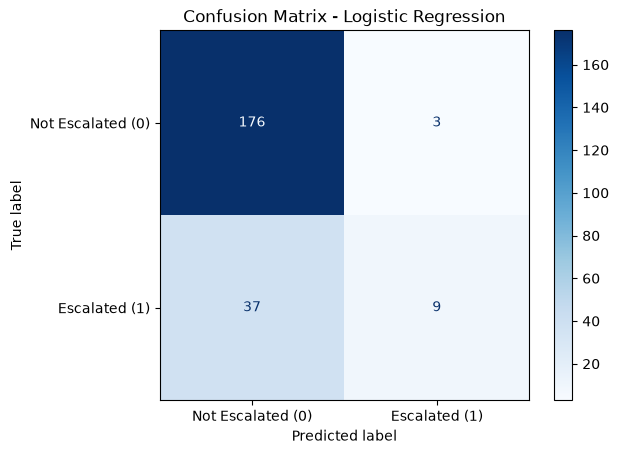

Confusion Matrix:
[[176   3]
 [ 37   9]]


In [19]:
# Get predictions from lg
y_pred_log = logistic_model.predict(X_test)


cm = confusion_matrix(y_test, y_pred_log)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Escalated (0)", "Escalated (1)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


print("Confusion Matrix:")
print(cm)


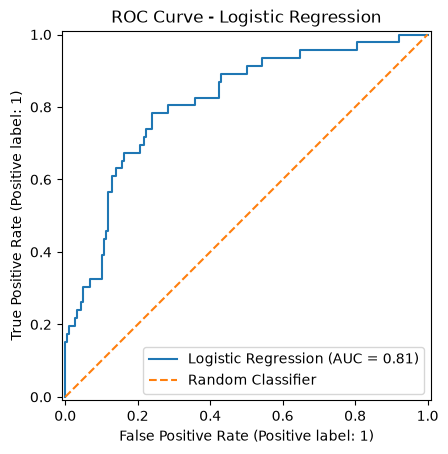

ROC-AUC: 0.8111


In [20]:
#predicted probabilities for the positive class
y_prob_log = logistic_model.predict_proba(X_test)[:, 1]

#ROC-AUC calc
auc_score = roc_auc_score(y_test, y_prob_log)

#ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_log,
    name="Logistic Regression"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

print("ROC-AUC:", round(auc_score, 4))


### Task 6:  Evaluate thresholds 0.20, 0.30, 0.40, 0.50, 0.60, and 0.70. Report precision, recall, F1, FP, and FN. 

A classification threshold is the probability value the model uses to make its final decision.

For example, if the model predicts that a ticket has a 70% chance of being escalated:

- With a threshold of 0.50, the model predicts escalated (1).
- With a threshold of 0.80, the model predicts not escalated (0).

By default, Logistic Regression uses a threshold of 0.50. In this task, we test different thresholds: 0.20, 0.30, 0.40, 0.50, 0.60, and 0.70.

For each threshold, we calculate precision, recall, F1-score, false positives (FP), and false negatives (FN) to see how the model's predictions change.

Lowering the threshold makes the model identify more tickets as escalated. This helps catch more actual escalated tickets (higher recall), but it can also create more false alarms (higher false positives). Raising the threshold makes the model more strict, reducing false alarms but potentially missing more escalated tickets.

In [21]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]


threshold_results = []

#evaluate each threshold
for threshold in thresholds:

    #convert probabilities -> class predictions
    y_pred_threshold = (y_prob_log >= threshold).astype(int)

    #precision, recall, and F1-score
    precision = precision_score(
        y_test, y_pred_threshold, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred_threshold, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred_threshold, zero_division=0
    )

    #confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred_threshold, labels=[0, 1]
    ).ravel()

    #save
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "FP": fp,
        "FN": fn
    })

# Converting it to DataFrame
threshold_df = pd.DataFrame(threshold_results)

print("Logistic Regression Threshold Comparison:")
display(threshold_df.round(4))

Logistic Regression Threshold Comparison:


,Threshold,Precision,Recall,F1-Score,FP,FN
0,0.2,0.4286,0.7826,0.5538,48,10
1,0.3,0.5490,0.6087,0.5773,23,18
2,0.4,0.5714,0.2609,0.3582,9,34
3,0.5,0.7500,0.1957,0.3103,3,37
4,0.6,1.0000,0.0652,0.1224,0,43
5,0.7,0.0000,0.0000,0.0000,0,46


## TASK7 Use the illustrative cost function 5×FN + 1×FP to compare thresholds. ● Use stratified 5-fold cross-validation on the training set and tune k-NN's k over 5, 9, 15, 21, and 31 using F1. 

We use the following illustrative cost function:

Total Cost = 5 × FN + 1 × FP

A false negative is assigned a cost of 5 because missing an escalated ticket
is considered more serious.

A false positive is assigned a cost of 1 because unnecessarily escalating
a ticket has a lower cost.

We calculate the total cost for each threshold and identify the threshold
with the lowest total cost.

In [22]:
#total cost for each threshold
threshold_df["Total Cost"] = (
    5 * threshold_df["FN"] + threshold_df["FP"]
)

print("Threshold Comparison with Total Cost:")
display(threshold_df.round(4))

#threshold with the minimum cost
best_cost_row = threshold_df.loc[
    threshold_df["Total Cost"].idxmin()
]

print("Best threshold:", best_cost_row["Threshold"])
print("Minimum total cost:", best_cost_row["Total Cost"])

Threshold Comparison with Total Cost:


,Threshold,Precision,Recall,F1-Score,FP,FN,Total Cost
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230


Best threshold: 0.2
Minimum total cost: 98.0


## TASK8 Model Recommendation for Ticket Escalation Prediction

Based on our results, I recommend Logistic Regression for predicting ticket escalation. It performed better than the other models, with 82.22% accuracy and an ROC-AUC of 0.8111. Logistic Regression and LDA had almost the same results, but Logistic Regression had a slightly higher ROC-AUC. KNN performed worse than both.

I recommend using a threshold of 0.20 instead of 0.50. This means the model will mark more tickets as escalated, even when the predicted probability is relatively low. At this threshold the model correctly identifies 78.26% of escalated tickets. Howwever, it also produces 48 false positives, meaning some tickets that do not need escalation will be marked as escalated.

I chose this threshold because missing an escalated ticket is considered five times more costly than incorrectly marking a ticket for escalation. Using our cost formula (5 × FN + FP), threshold 0.20 gives the lowest cost of 98 among the tested thresholds. Although threshold 0.30 gives a higher F1-score, threshold 0.20 is better for our chosen cost condition.

However, there are some limitations. Our dataset has only 900 tickets, and most of them are not escalated. Also, the dataset is synthetic, so it may not represent real ticket situations. We also used the testing data to choose the threshold, which may make our results look better than they actually are. We should use separate validation data to choose the threshold.

Before using this model in real situations, we should also consider privacy and fairness. The model might make unfair predictions based on features such as customer tenure, priority, or communication channel. Therefore, staff should review the predictions instead of allowing the model to make decisions by itself. We should also test it with real data and check its performance regularly.

Overall, I recommend Logistic Regression with a 0.20 threshold because it identifies more escalated tickets and has the lowest error cost in our results. However, it needs more testing before using it in real life just to be sure.

## **4. Questions and Answers**

**1. Why is accuracy alone potentially misleading?**

Accuracy measures the percentage of all predictions that are correct, but it does not tell us whether the model can correctly identify both classes.

In our dataset, 79.33% of tickets are not escalated, while only 20.67% are escalated. The Majority Baseline achieved 79.56% accuracy simply by predicting every ticket as not escalated. However, its recall was 0%, meaning it failed to identify even one escalated ticket.

This shows that a model can have high accuracy while being useless for finding the tickets we actually want to detect. Therefore, we should also consider precision, recall, and F1-score, especially because identifying escalated tickets is important for this task.

**2. Which classifier has the strongest recall, precision, and F1?**

From our initial model comparison, Logistic Regression and LDA achieved the same results:

- **Recall:** Both achieved 19.57%.
- **Precision:** Both achieved 75%.
- **F1-score:** Both achieved 0.3103.

This means that both models correctly identified only 19.57% of all escalated tickets. However, when either model predicted that a ticket would be escalated, it was correct 75% of the time.

Their F1-scores are also equal because they have the same precision and recall. Logistic Regression had a slightly higher ROC-AUC of 0.8111 compared with LDA's 0.8090.

Therefore, Logistic Regression and LDA are tied in precision, recall, and F1-score, while Logistic Regression performs slightly better in ROC-AUC. This makes Logistic Regression a reasonable choice for further evaluation.

**3. What changes when the threshold is lowered?**

The threshold determines how much predicted probability the model needs before classifying a ticket as escalated.

When we lower the threshold, the model becomes less strict about predicting escalation. More tickets are classified as escalated, including some tickets that would previously have been classified as not escalated.

Our results show this clearly when we lower the threshold from 0.50 to 0.20:

- Recall increases from 19.57% to 78.26%.
- False negatives decrease from 37 to 10.
- False positives increase from 3 to 48.

The increase in recall means that the model now identifies many more of the actual escalated tickets. However, the increase in false positives means that more non-escalated tickets are incorrectly flagged.

Therefore, lowering the threshold helps us catch more escalated tickets, but it also creates more false alarms. The appropriate threshold depends on which type of mistake is more costly.

**4. Which threshold minimizes 5 × FN + FP, and why might the estimate be optimistic?**

The **0.20 threshold** gives the lowest cost of **98** among the thresholds we tested.

Our cost formula is:

\\[ Cost = 5 \times FN + FP \\]

This formula assigns a cost of 5 to every false negative and a cost of 1 to every false positive. This means missing an actually escalated ticket is considered five times more expensive than incorrectly flagging a non-escalated ticket.

At threshold 0.20, we had 10 false negatives and 48 false positives:

\\[ Cost = 5(10) + 48 = 98 \\]

Although this threshold produces more false positives, it reduces false negatives enough to give us the lowest total cost.

However, this estimate may be optimistic because we used the test set to compare thresholds and select the one with the lowest cost. Once we repeatedly make decisions based on test results, we may start choosing a threshold that works particularly well for that specific test set. It may not perform equally well on new data.

A better approach is to select the threshold using validation data or cross-validation, then use the test set only for the final evaluation.

**5. Explain prior, likelihood, posterior, and evidence.**

These are the four main parts of Bayes' theorem. They explain how we use existing knowledge and new information to estimate the probability that a ticket will be escalated.

Consider a ticket with high complexity, high priority, and low team experience.

- **Prior:** The probability of escalation before examining the individual ticket's features. In our dataset, this is 20.67%.
- **Likelihood:** The probability of observing those particular features if a ticket is actually escalated. For example, how likely is a high-complexity ticket if it belongs to the escalated class?
- **Evidence:** The overall probability of observing those features across all tickets, whether escalated or not.
- **Posterior:** The updated probability that the ticket will be escalated after considering its features.

Bayes' theorem combines these values:

\\[ P(E|X)=\frac{P(X|E)\times P(E)}{P(X)} \\]

Where \\(E\\) means escalation and \\(X\\) represents the ticket features.

The important idea is that we start with the general escalation rate (prior), examine the ticket information (likelihood), and update our probability to get the posterior. The evidence accounts for how common those features are overall.

**6. Given P(escalated|x) = 0.30, compare expected costs and derive the threshold.**

We are given that the probability of escalation is 0.30. Therefore, the probability that the ticket is not escalated is:

\\[ P(Not\ escalated|x)=1-0.30=0.70 \\]

We have two possible decisions.

**Decision 1: Escalate the ticket**

If we escalate, we make a mistake only if the ticket is actually not escalated. This is a false positive, with a cost of 1.

\\[ Expected\ Cost = 0.70 \times 1 = 0.70 \\]

**Decision 2: Do not escalate the ticket**

If we do not escalate, we make a mistake if the ticket is actually escalated. This is a false negative, with a cost of 5.

\\[ Expected\ Cost = 0.30 \times 5 = 1.50 \\]

We compare the two expected costs:

- Escalate: 0.70
- Do not escalate: 1.50

Since 0.70 is lower than 1.50, we should **escalate the ticket**.

**Deriving the cost-sensitive threshold**

Let \\(p\\) be the predicted probability of escalation.

- Expected cost of escalating = \\((1-p)\times FP\ Cost\\)
- Expected cost of not escalating = \\(p\times FN\ Cost\\)

We choose escalation when:

\\[ (1-p)\times FP\ Cost < p\times FN\ Cost \\]

Rearranging:

\\[ p > \frac{FP\ Cost}{FP\ Cost+FN\ Cost} \\]

Substituting our costs:

\\[ Threshold = \frac{1}{1+5}=0.1667 \\]

Therefore, the cost-sensitive threshold is approximately **16.67%**. We should predict escalation when the predicted probability is greater than this threshold because, under the given costs, doing so gives us a lower expected error cost.

**7. Which model would you recommend for deployment, and what further checks are required?**

Based on our current results, I recommend **Logistic Regression with a threshold of 0.20** as a starting point.

There are two main reasons for this choice. First, Logistic Regression achieved an ROC-AUC of 0.8111, which was slightly higher than LDA and better than KNN and the majority baseline. This indicates that it can distinguish between escalated and non-escalated tickets reasonably well.

Second, changing its threshold to 0.20 increased recall to 78.26% and reduced false negatives from 37 to 10. Since missing an escalated ticket is five times more costly in our evaluation, reducing false negatives is important. The threshold also produced the lowest calculated cost of 98 among the tested thresholds.

However, this does not mean the model is ready for immediate deployment. Before using it in a real ticket system, we should:

1. **Test with real data:** Our dataset is synthetic, so we need to check whether the model works with actual ticket records.
2. **Compare with tuned KNN:** We should evaluate whether the KNN model improves after selecting its best value of k through cross-validation.
3. **Check fairness:** We should investigate whether the model produces unfair results for different customers or ticket groups.
4. **Protect privacy:** Customer information used for predictions should be handled securely.
5. **Monitor performance:** We should regularly check whether prediction quality changes as new tickets and working conditions change.
6. **Keep human review:** Staff should be able to review the model's predictions, especially for important escalation decisions.

Overall, Logistic Regression with a 0.20 threshold is a reasonable preliminary choice because it gives us a good balance between identifying escalated tickets and controlling the cost of mistakes. However, it should be tested further before being used in a real environment.